In [2]:
# 1
import gc
import torch

# Clear Python garbage
gc.collect()

# Clear CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("GPU memory cleared.")

GPU memory cleared.


In [3]:
# 2
if torch.cuda.is_available():
    print(torch.cuda.memory_summary())
else:
    print("CUDA is not available.")

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [4]:
# 3
# ==========================================
# NeurALLNet Version-04
# Environment Setup
# ==========================================
!pip install -q spikingjelly
import spikingjelly
import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from spikingjelly.activation_based import neuron, surrogate, functional

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("NeurALLNet Version-04")
print("======================")
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

NeurALLNet Version-04
PyTorch: 2.11.0+cu128
CUDA Available: True
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


In [5]:
# 4

print("Kaggle input directories:\n")

for item in os.listdir("/kaggle/input"):
    print(item)

Kaggle input directories:

datasets


In [6]:
# 5
DATA_ROOT = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:8]:
        print(f"{indent}    {file}")

    if len(files) > 8:
        print(f"{indent}    ... and {len(files)-8} more files")

datasets/
    faiznadeem39/
        milk10k/
            MILK10k_Training_GroundTruth.csv
            MILK10k_Training_Metadata.csv
            MILK10k_Training_Supplement.csv
            MILK10k_Training_Input/


In [7]:
# 6
# ==========================================
# Dataset Path Configuration
# ==========================================

DATA_ROOT = "/kaggle/input/datasets/faiznadeem39/milk10k"

GROUND_TRUTH_CSV = os.path.join(
    DATA_ROOT, "MILK10k_Training_GroundTruth.csv"
)

METADATA_CSV = os.path.join(
    DATA_ROOT, "MILK10k_Training_Metadata.csv"
)

IMAGE_ROOT = os.path.join(
    DATA_ROOT,
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

# Verify paths
print("Ground Truth:", os.path.exists(GROUND_TRUTH_CSV))
print("Metadata:", os.path.exists(METADATA_CSV))
print("Image Root:", os.path.exists(IMAGE_ROOT))

print("\nImage directory contents:")
if os.path.exists(IMAGE_ROOT):
    print(os.listdir(IMAGE_ROOT)[:10])

Ground Truth: True
Metadata: True
Image Root: True

Image directory contents:
['IL_0000652', 'IL_0003176', 'IL_0004688', 'IL_0005081', 'IL_0006177', 'IL_0006407', 'IL_0008891', 'IL_0008969', 'IL_0009339', 'IL_0011263']


In [8]:
# 7
# ==========================================
# Load MILK10k CSV Files
# ==========================================

ground_truth_df = pd.read_csv(GROUND_TRUTH_CSV)
metadata_df = pd.read_csv(METADATA_CSV)


print("GROUND TRUTH")
print("Shape:", ground_truth_df.shape)
print("Columns:", ground_truth_df.columns.tolist())
display(ground_truth_df.head())

print("\nMETADATA")
print("Shape:", metadata_df.shape)
print("Columns:", metadata_df.columns.tolist())
display(metadata_df.head())


GROUND TRUTH
Shape: (5240, 12)
Columns: ['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0005081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,IL_0006177,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



METADATA
Shape: (10480, 17)
Columns: ['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']


,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,MONET_ulceration_crust,MONET_hair,MONET_vasculature_vessels,MONET_erythema,MONET_pigmented,MONET_gel_water_drop_fluid_dermoscopy_liquid,MONET_skin_markings_pen_ink_purple_pen
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70.0,male,1,head_neck_face,0.166749,0.163601,0.002284,0.124315,0.719495,0.220399,0.237601
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70.0,male,1,head_neck_face,0.659859,0.156478,0.016397,0.032357,0.847014,0.138121,0.148776
2,IL_0003176,clinical: close-up,ISIC_3904045,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.348609,0.614718,0.013415,0.447485,0.061977,0.296341,0.058006
3,IL_0003176,dermoscopic,ISIC_5371928,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,0.392950,0.897668,0.367882,0.645776,0.122108,0.719937,0.329812
4,IL_0004688,clinical: close-up,ISIC_0791494,MILK study team,CC-BY-NC,instrument only,50.0,male,3,lower_extremity,0.889925,0.120788,0.004546,0.487298,0.036550,0.146776,0.086027


In [9]:
# 8
# ==========================================
# Original Class Distribution
# ==========================================

class_columns = [
    col for col in ground_truth_df.columns
    if col != "lesion_id"
]

class_counts = ground_truth_df[class_columns].sum().astype(int)

print("Total lesions:", len(ground_truth_df))
print("Total classes:", len(class_columns))

print("\nOriginal Class Distribution:\n")

for class_name, count in class_counts.items():
    print(f"{class_name:10s}: {count}")

print("\nTotal samples:", class_counts.sum())

Total lesions: 5240
Total classes: 11

Original Class Distribution:

AKIEC     : 303
BCC       : 2522
BEN_OTH   : 44
BKL       : 544
DF        : 52
INF       : 50
MAL_OTH   : 9
MEL       : 450
NV        : 746
SCCKA     : 473
VASC      : 47

Total samples: 5240


In [10]:
# 9
# ==========================================
# NeurALLNet V04 - Correct five Class Filtering
# ==========================================

class_names = ["BCC", "NV", "BKL", "SCCKA", "MEL"]

# Select the five target classes
filtered_gt = ground_truth_df[
    ["lesion_id"] + class_names
].copy()

# Remove lesions belonging to excluded classes
filtered_gt = filtered_gt[filtered_gt[class_names].sum(axis=1) == 1].copy()

# Assign class labels
filtered_gt["label"] = filtered_gt[class_names].idxmax(axis=1)

# Encode labels
label_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

filtered_gt["label_idx"] = filtered_gt["label"].map(label_to_idx)

print("Retained lesions:", len(filtered_gt))

print("\nClass distribution:")
print(filtered_gt["label"].value_counts().reindex(class_names))

print("\nMissing labels:", filtered_gt["label_idx"].isna().sum())
print("Duplicate lesion IDs:", filtered_gt["lesion_id"].duplicated().sum())

Retained lesions: 4735

Class distribution:
label
BCC      2522
NV        746
BKL       544
SCCKA     473
MEL       450
Name: count, dtype: int64

Missing labels: 0
Duplicate lesion IDs: 0


In [11]:
# 10
paired_metadata = metadata_df[
    metadata_df["lesion_id"].isin(filtered_gt["lesion_id"])
].copy()

print("Image type distribution:")
print(paired_metadata["image_type"].value_counts())

print("\nUnique lesions:", paired_metadata["lesion_id"].nunique())

print("\nDuplicate lesion-image type pairs:",
      paired_metadata.duplicated(
          subset=["lesion_id", "image_type"]
      ).sum())

print("\nImage types:", paired_metadata["image_type"].unique())

Image type distribution:
image_type
clinical: close-up    4735
dermoscopic           4735
Name: count, dtype: int64

Unique lesions: 4735

Duplicate lesion-image type pairs: 0

Image types: ['clinical: close-up' 'dermoscopic']


In [12]:
# 11
paired_images = paired_metadata.pivot(
    index="lesion_id",
    columns="image_type",
    values="isic_id"
).reset_index()

paired_df = filtered_gt[
    ["lesion_id", "label", "label_idx"]
].merge(
    paired_images,
    on="lesion_id",
    how="inner",
    validate="one_to_one"
)

paired_df = paired_df.rename(columns={
    "clinical: close-up": "clinical_image",
    "dermoscopic": "dermoscopic_image"
})

print("Paired dataset shape:", paired_df.shape)
print("\nMissing clinical images:",
      paired_df["clinical_image"].isna().sum())
print("Missing dermoscopic images:",
      paired_df["dermoscopic_image"].isna().sum())

display(paired_df.head())

Paired dataset shape: (4735, 5)

Missing clinical images: 0
Missing dermoscopic images: 0


,lesion_id,label,label_idx,clinical_image,dermoscopic_image
0,IL_0000652,BCC,0,ISIC_8149219,ISIC_4671410
1,IL_0003176,BCC,0,ISIC_3904045,ISIC_5371928
2,IL_0004688,BCC,0,ISIC_0791494,ISIC_3624913
3,IL_0005081,SCCKA,3,ISIC_5667730,ISIC_5186409
4,IL_0006177,BCC,0,ISIC_8803389,ISIC_1048297


In [13]:
# 12
# Verify actual image files for sample lesions

for _, row in paired_df.head(5).iterrows():

    lesion_folder = os.path.join(
        IMAGE_ROOT, row["lesion_id"]
    )

    files = os.listdir(lesion_folder)

    clinical_exists = any(
        f.startswith(row["clinical_image"])
        for f in files
    )

    dermoscopic_exists = any(
        f.startswith(row["dermoscopic_image"])
        for f in files
    )

    print(
        row["lesion_id"],
        "| Clinical:", clinical_exists,
        "| Dermoscopic:", dermoscopic_exists
    )

IL_0000652 | Clinical: True | Dermoscopic: True
IL_0003176 | Clinical: True | Dermoscopic: True
IL_0004688 | Clinical: True | Dermoscopic: True
IL_0005081 | Clinical: True | Dermoscopic: True
IL_0006177 | Clinical: True | Dermoscopic: True


In [14]:
# 13
from sklearn.model_selection import train_test_split

# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    paired_df,
    test_size=0.20,
    random_state=42,
    stratify=paired_df["label_idx"]
)

# Second split: 10% validation, 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label_idx"]
)

# Verify split sizes
print("========== DATA SPLIT ==========")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

# Verify class distribution
for split_name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{split_name} CLASS DISTRIBUTION:")
    print(
        split_df["label"].value_counts()
        .reindex(class_names, fill_value=0)
    )

# Verify lesion-level separation
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

print("\n========== OVERLAP CHECK ==========")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

========== DATA SPLIT ==========
Training: 3788
Validation: 473
Testing: 474
Total: 4735

TRAIN CLASS DISTRIBUTION:
label
BCC      2018
NV        597
BKL       435
SCCKA     378
MEL       360
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION:
label
BCC      252
NV        74
BKL       54
SCCKA     48
MEL       45
Name: count, dtype: int64

TEST CLASS DISTRIBUTION:
label
BCC      252
NV        75
BKL       55
SCCKA     47
MEL       45
Name: count, dtype: int64

========== OVERLAP CHECK ==========
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [15]:
# 14
# Training-only class weights
train_counts = (
    train_df["label_idx"]
    .value_counts()
    .reindex(range(len(class_names)))
)

counts_tensor = torch.tensor(
    train_counts.values,
    dtype=torch.float32
)

# Inverse-frequency weights
alpha = 1.0 / counts_tensor

# Normalize alpha to mean 1
alpha = alpha / alpha.mean()

alpha = alpha.to(device)

GAMMA = 2.0

print("Training class counts:")
print(train_counts)

print("\nFocal Loss alpha weights:")
for name, weight in zip(class_names, alpha.cpu().numpy()):
    print(f"{name:8s}: {weight:.4f}")

print("\nAlpha mean:", alpha.mean().item())
print("Gamma:", GAMMA)

Training class counts:
label_idx
0    2018
1     597
2     435
3     378
4     360
Name: count, dtype: int64

Focal Loss alpha weights:
BCC     : 0.2505
NV      : 0.8466
BKL     : 1.1619
SCCKA   : 1.3371
MEL     : 1.4040

Alpha mean: 1.0
Gamma: 2.0


In [16]:
# 15
sample_lesion = paired_df.iloc[0]["lesion_id"]

sample_folder = os.path.join(IMAGE_ROOT, sample_lesion)

print("Lesion:", sample_lesion)
print("\nFiles:")

for filename in os.listdir(sample_folder):
    print(filename)

Lesion: IL_0000652

Files:
ISIC_4671410.jpg
ISIC_8149219.jpg


In [24]:
# 16
    # ==========================================
    # Paired Dataset and Augmentation - Version 4-c
    # No Random Augmentation
    # ==========================================
    
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF


# ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


# ==========================================
# Paired Transform (No Augmentation)
# ==========================================

class PairedTransform:

    def __init__(self, size=224):
        self.size = size

    def __call__(self, clinical, dermoscopic):

        # Resize both modalities
        clinical = TF.resize(
            clinical, (self.size, self.size)
        )

        dermoscopic = TF.resize(
            dermoscopic, (self.size, self.size)
        )

        # Convert to tensors
        clinical = TF.to_tensor(clinical)
        dermoscopic = TF.to_tensor(dermoscopic)

        # ImageNet normalization
        clinical = TF.normalize(
            clinical, MEAN, STD
        )

        dermoscopic = TF.normalize(
            dermoscopic, MEAN, STD
        )

        return clinical, dermoscopic


# ==========================================
# Paired MILK10k Dataset
# ==========================================

class MILK10kPairedDataset(Dataset):

    def __init__(self, dataframe, image_root, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_root = image_root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        lesion_folder = os.path.join(
            self.image_root, row["lesion_id"]
        )

        clinical_path = os.path.join(
            lesion_folder, row["clinical_image"] + ".jpg"
        )

        dermoscopic_path = os.path.join(
            lesion_folder, row["dermoscopic_image"] + ".jpg"
        )

        clinical = Image.open(clinical_path).convert("RGB")
        dermoscopic = Image.open(dermoscopic_path).convert("RGB")

        if self.transform:
            clinical, dermoscopic = self.transform(
                clinical, dermoscopic
            )

        label = torch.tensor(
            row["label_idx"], dtype=torch.long
        )

        return clinical, dermoscopic, label


# ==========================================
# Define Transformations
# ==========================================

train_transform = PairedTransform(size=224)

val_test_transform = PairedTransform(size=224)


# ==========================================
# Create Datasets
# ==========================================

train_dataset = MILK10kPairedDataset(
    train_df, IMAGE_ROOT, train_transform
)

val_dataset = MILK10kPairedDataset(
    val_df, IMAGE_ROOT, val_test_transform
)

test_dataset = MILK10kPairedDataset(
    test_df, IMAGE_ROOT, val_test_transform
)


print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

print("\nPaired datasets created successfully.")
print("Random augmentation: DISABLED")
print("Image size: 224 x 224")
print("Normalization: ImageNet")


Train dataset: 3788
Validation dataset: 473
Test dataset: 474

Paired datasets created successfully.
Random augmentation: DISABLED
Image size: 224 x 224
Normalization: ImageNet


In [25]:
# 17
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Verify one batch
clinical, dermoscopic, labels = next(iter(train_loader))

print("\nClinical:", clinical.shape)
print("Dermoscopic:", dermoscopic.shape)
print("Labels:", labels.shape)
print("Label values:", labels.unique().tolist())

Train batches: 474
Validation batches: 60
Test batches: 60

Clinical: torch.Size([8, 3, 224, 224])
Dermoscopic: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])
Label values: [0, 1, 2, 3]


In [26]:
# 18
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.gamma = gamma

        if alpha is not None:
            self.register_buffer("alpha", alpha)
        else:
            self.alpha = None

    def forward(self, inputs, targets):

        log_probs = torch.nn.functional.log_softmax(
            inputs, dim=1
        )

        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()

        focal_factor = (1.0 - pt) ** self.gamma

        loss = -focal_factor * log_pt

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * loss

        return loss.mean()


criterion = FocalLoss(
    alpha=alpha,
    gamma=GAMMA
).to(device)

print("Loss:", criterion.__class__.__name__)
print("Gamma:", criterion.gamma)
print("Alpha:", criterion.alpha)

Loss: FocalLoss
Gamma: 2.0
Alpha: tensor([0.2505, 0.8466, 1.1619, 1.3371, 1.4040], device='cuda:0')


In [27]:
# 19
# Focal Loss sanity check
sample_logits = torch.randn(
    8, len(class_names),
    device=device,
    requires_grad=True
)

sample_labels = torch.randint(
    0, len(class_names), (8,),
    device=device
)

sample_loss = criterion(sample_logits, sample_labels)

sample_loss.backward()

print("Sample loss:", sample_loss.item())
print("Loss is finite:", torch.isfinite(sample_loss).item())
print("Gradients available:", sample_logits.grad is not None)
print("Gradients finite:", torch.isfinite(sample_logits.grad).all().item())

Sample loss: 2.026808261871338
Loss is finite: True
Gradients available: True
Gradients finite: True


In [28]:
# 20
import torch
import torch.nn as nn
from spikingjelly.activation_based import neuron, surrogate, functional


# 1. Squeeze-and-Excitation Block
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()

        mid = max(channels // reduction, 8)

        self.squeeze = nn.AdaptiveAvgPool2d(1)

        self.excitation = nn.Sequential(
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape

        weights = self.squeeze(x).view(b, c)
        weights = self.excitation(weights).view(b, c, 1, 1)

        return x * weights


# 2. Depthwise Separable Convolution
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.depthwise = nn.Conv2d(
            in_ch,
            in_ch,
            kernel_size=3,
            padding=1,
            groups=in_ch,
            bias=False
        )

        self.bn_dw = nn.BatchNorm2d(in_ch)

        self.pointwise = nn.Conv2d(
            in_ch,
            out_ch,
            kernel_size=1,
            bias=False
        )

        self.bn_pw = nn.BatchNorm2d(out_ch)

    def forward(self, x):
        x = self.bn_dw(self.depthwise(x))
        x = self.bn_pw(self.pointwise(x))

        return x


# 3. Spiking Block
class SpikeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tau=2.0):
        super().__init__()

        self.conv = DepthwiseSeparableConv(in_ch, out_ch)

        self.se = SEBlock(out_ch)

        self.lif = neuron.LIFNode(
            tau=tau,
            v_threshold=1.0,
            surrogate_function=surrogate.ATan(alpha=2.0),
            step_mode='s'
        )

        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x = self.conv(x)
        x = self.se(x)
        x = self.lif(x)
        x = self.pool(x)

        return x


# 4. NeurALLNet Feature Extractor
class NeurALLFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()

        tau = 2.0

        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 48,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(48),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),

            nn.MaxPool2d(2, 2)
        )

        self.block1 = SpikeBlock(48, 96, tau)
        self.block2 = SpikeBlock(96, 192, tau)
        self.block3 = SpikeBlock(192, 384, tau)

        self.refine = nn.Sequential(
            nn.Conv2d(
                384, 384,
                kernel_size=3,
                padding=1,
                groups=384,
                bias=False
            ),
            nn.BatchNorm2d(384),

            nn.Conv2d(
                384, 256,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(256),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            )
        )

        self.gap = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.refine(x)
        x = self.gap(x).flatten(1)

        return x


# 5. Dual-Branch NeurALLNet
class DualBranchNeurALLNet(nn.Module):

    def __init__(self, num_classes=6, time_steps=4):
        super().__init__()

        self.T = time_steps

        self.clinical_branch = NeurALLFeatureExtractor()
        self.dermoscopic_branch = NeurALLFeatureExtractor()

        self.classifier = nn.Sequential(
            nn.Linear(512, 128, bias=False),
            nn.BatchNorm1d(128),
            neuron.LIFNode(
                tau=2.0,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes, bias=False)
        )

    def forward(self, clinical, dermoscopic):

        functional.reset_net(self)

        output_sum = None

        for t in range(self.T):

            clinical_features = self.clinical_branch(clinical)

            dermoscopic_features = self.dermoscopic_branch(
                dermoscopic
            )

            fused_features = torch.cat(
                (clinical_features, dermoscopic_features),
                dim=1
            )

            output = self.classifier(fused_features)

            if output_sum is None:
                output_sum = output
            else:
                output_sum = output_sum + output

        return output_sum / self.T


print("All architecture classes defined successfully.")


All architecture classes defined successfully.


In [29]:
# 21
model = DualBranchNeurALLNet(
    num_classes=len(class_names),
    time_steps=4
).to(device)

In [30]:
# 22
# Forward Pass Verification

model.eval()

clinical_batch, dermoscopic_batch, labels = next(iter(train_loader))

clinical_batch = clinical_batch.to(device)
dermoscopic_batch = dermoscopic_batch.to(device)

with torch.no_grad():
    functional.reset_net(model)
    outputs = model(clinical_batch, dermoscopic_batch)

print("Clinical input shape:", clinical_batch.shape)
print("Dermoscopic input shape:", dermoscopic_batch.shape)
print("Labels shape:", labels.shape)
print("Model output shape:", outputs.shape)

print("\nExpected output shape:", (8, 6))
print("Forward pass successful:", outputs.shape == (8, 6))

Clinical input shape: torch.Size([8, 3, 224, 224])
Dermoscopic input shape: torch.Size([8, 3, 224, 224])
Labels shape: torch.Size([8])
Model output shape: torch.Size([8, 5])

Expected output shape: (8, 6)
Forward pass successful: False


In [31]:
# 23
import torch.optim as optim

learning_rate = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

In [32]:
# 24

# ==========================================
# NeurALLNet V04-D
# Training Configuration and History
# ==========================================

NUM_EPOCHS = 50
PATIENCE = 10

best_val_f1 = 0.0
early_stop_counter = 0

history = {
    # Original training-step metrics
    "train_batch_loss": [],
    "train_batch_acc": [],
    "train_batch_f1": [],

    # Corrected training evaluation metrics
    "train_loss": [],
    "train_acc": [],
    "train_f1": [],

    # Validation metrics
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("NeurALLNet V04-D")
print("==========================")
print("Epochs:", NUM_EPOCHS)
print("Early Stopping Patience:", PATIENCE)
print("Checkpoint Selection Metric: Validation Macro F1")
print("Training Evaluation: Corrected evaluation after each epoch")
print("Training augmentation: Disabled")

NeurALLNet V04-D
Epochs: 50
Early Stopping Patience: 10
Checkpoint Selection Metric: Validation Macro F1
Training Evaluation: Corrected evaluation after each epoch
Training augmentation: Disabled


In [34]:

# ==========================================
# NeurALLNet Version-04-D
# Training Loop with Corrected Training Evaluation
# Macro F1 Checkpointing
# ==========================================



# ==========================================
# Checkpoint Directory
# ==========================================

CHECKPOINT_DIR = "checkpoints_v4_d"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

class_indices = list(range(len(class_names)))

best_val_f1 = -1.0
early_stop_counter = 0


# ==========================================
# Evaluation Function
# ==========================================

def evaluate_model(model, data_loader, criterion, device, class_indices):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for clinical, dermoscopic, labels in data_loader:

            clinical = clinical.to(device)
            dermoscopic = dermoscopic.to(device)
            labels = labels.to(device)

            outputs = model(clinical, dermoscopic)

            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predictions.cpu().numpy())

            functional.reset_net(model)

            del clinical, dermoscopic, labels
            del outputs, loss, predictions

    avg_loss = total_loss / total_samples

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        labels=class_indices,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


# ==========================================
# TRAINING LOOP
# ==========================================

for epoch in range(NUM_EPOCHS):

    # ======================================
    # TRAINING PHASE
    # ======================================

    model.train()

    train_batch_losses = []
    train_batch_labels = []
    train_batch_preds = []

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
    )

    for clinical, dermoscopic, labels in train_bar:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(clinical, dermoscopic)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_batch_losses.append(loss.item())

        predictions = torch.argmax(
            outputs.detach(),
            dim=1
        )

        train_batch_labels.extend(
            labels.detach().cpu().numpy()
        )

        train_batch_preds.extend(
            predictions.cpu().numpy()
        )

        functional.reset_net(model)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

        del clinical, dermoscopic, labels
        del outputs, loss, predictions

    # ======================================
    # ONLINE TRAINING METRICS
    # ======================================

    train_batch_loss = np.mean(train_batch_losses)

    train_batch_acc = accuracy_score(
        train_batch_labels,
        train_batch_preds
    )

    train_batch_f1 = f1_score(
        train_batch_labels,
        train_batch_preds,
        labels=class_indices,
        average="macro",
        zero_division=0
    )

    # ======================================
    # POST-EPOCH TRAINING EVALUATION
    # ======================================

    train_loss, train_acc, train_f1 = evaluate_model(
        model,
        train_loader,
        criterion,
        device,
        class_indices
    )

    # ======================================
    # VALIDATION
    # ======================================

    val_loss, val_acc, val_f1 = evaluate_model(
        model,
        val_loader,
        criterion,
        device,
        class_indices
    )

    # ======================================
    # SAVE TRAINING HISTORY
    # ======================================

    history["train_batch_loss"].append(train_batch_loss)
    history["train_batch_acc"].append(train_batch_acc)
    history["train_batch_f1"].append(train_batch_f1)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # ======================================
    # EPOCH RESULTS
    # ======================================

    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")

    print(
        f"Train Eval Loss: {train_loss:.4f} | "
        f"Train Eval Acc: {train_acc:.4f} | "
        f"Train Eval Macro F1: {train_f1:.4f}"
    )

    print(
        f"Train Batch Acc: {train_batch_acc:.4f} | "
        f"Train Batch Macro F1: {train_batch_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    # ======================================
    # BEST MODEL CHECKPOINT
    # ======================================

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        early_stop_counter = 0

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_f1": best_val_f1,
            "class_names": class_names,
            "history": history
        }

        torch.save(
            checkpoint,
            os.path.join(CHECKPOINT_DIR, "best_model.pth")
        )

        print(
            f"Best model saved! "
            f"Validation Macro F1: {best_val_f1:.4f}"
        )

    else:

        early_stop_counter += 1

        print(
            f"No improvement: "
            f"{early_stop_counter}/{PATIENCE}"
        )

    # ======================================
    # EARLY STOPPING
    # ======================================

    if early_stop_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

    # ======================================
    # MEMORY CLEANUP
    # ======================================

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ==========================================
# TRAINING COMPLETED
# ==========================================

print("\nTraining completed.")

print(
    f"Best Validation Macro F1: {best_val_f1:.4f}"
)

print(
    f"Best model location: "
    f"{CHECKPOINT_DIR}/best_model.pth"
)


Epoch 1/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch [1/50]
Train Eval Loss: 0.4925 | Train Eval Acc: 0.5583 | Train Eval Macro F1: 0.3860
Train Batch Acc: 0.4374 | Train Batch Macro F1: 0.3381
Val Loss: 0.5090 | Val Acc: 0.5518 | Val Macro F1: 0.3918
Best model saved! Validation Macro F1: 0.3918


Epoch 2/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch [2/50]
Train Eval Loss: 0.4550 | Train Eval Acc: 0.5940 | Train Eval Macro F1: 0.4280
Train Batch Acc: 0.4665 | Train Batch Macro F1: 0.3742
Val Loss: 0.4775 | Val Acc: 0.5962 | Val Macro F1: 0.4445
Best model saved! Validation Macro F1: 0.4445


Epoch 3/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch [3/50]
Train Eval Loss: 0.4300 | Train Eval Acc: 0.5797 | Train Eval Macro F1: 0.4667
Train Batch Acc: 0.4826 | Train Batch Macro F1: 0.3898
Val Loss: 0.4529 | Val Acc: 0.5751 | Val Macro F1: 0.4696
Best model saved! Validation Macro F1: 0.4696


... (16 outputs left out)

Epoch 12/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch [12/50]
Train Eval Loss: 0.4603 | Train Eval Acc: 0.5248 | Train Eval Macro F1: 0.4132
Train Batch Acc: 0.5346 | Train Batch Macro F1: 0.4581
Val Loss: 0.4558 | Val Acc: 0.5095 | Val Macro F1: 0.4026
No improvement: 9/10


Epoch 13/50 [Train]:   0%|          | 0/474 [00:00<?, ?it/s]


Epoch [13/50]
Train Eval Loss: 0.4117 | Train Eval Acc: 0.5568 | Train Eval Macro F1: 0.4598
Train Batch Acc: 0.5259 | Train Batch Macro F1: 0.4507
Val Loss: 0.4483 | Val Acc: 0.5074 | Val Macro F1: 0.4184
No improvement: 10/10

Early stopping triggered.

Training completed.
Best Validation Macro F1: 0.4696
Best model location: checkpoints_v4_d/best_model.pth


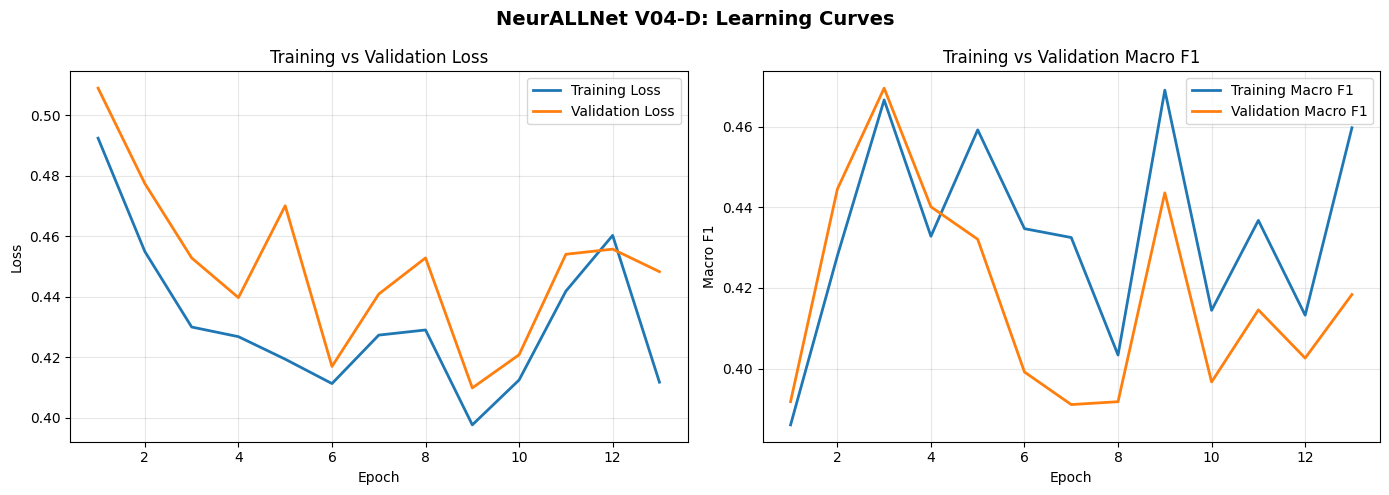

Total epochs completed: 13
Best Validation Macro F1: 0.4696


In [37]:

# ==========================================
# NeurALLNet Version-04-D
# Training and Validation Curves
# ==========================================

import matplotlib.pyplot as plt

# Epoch numbers
epochs = range(1, len(history["train_loss"]) + 1)

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ==========================================
# 1. Training and Validation Loss
# ==========================================

axes[0].plot(
    epochs,
    history["train_loss"],
    label="Training Loss",
    linewidth=2
)

axes[0].plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# ==========================================
# 2. Training and Validation Macro F1
# ==========================================

axes[1].plot(
    epochs,
    history["train_f1"],
    label="Training Macro F1",
    linewidth=2
)

axes[1].plot(
    epochs,
    history["val_f1"],
    label="Validation Macro F1",
    linewidth=2
)

axes[1].set_title("Training vs Validation Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(True, alpha=0.3)


# ==========================================
# Final Figure
# ==========================================

plt.suptitle(
    "NeurALLNet V04-D: Learning Curves",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


print(f"Total epochs completed: {len(history['train_loss'])}")
print(f"Best Validation Macro F1: {best_val_f1:.4f}")


Best checkpoint loaded successfully.
Best epoch: 3
Best validation Macro F1: 0.4696

VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

         BCC     0.7600    0.6786    0.7170       252
          NV     0.5806    0.7297    0.6467        74
         BKL     0.1500    0.2222    0.1791        54
       SCCKA     0.4286    0.5000    0.4615        48
         MEL     0.5789    0.2444    0.3438        45

    accuracy                         0.5751       473
   macro avg     0.4996    0.4750    0.4696       473
weighted avg     0.6114    0.5751    0.5831       473


Confusion Matrix:
[[171  10  47  22   2]
 [  8  54   8   2   2]
 [ 26   9  12   3   4]
 [ 13   0  11  24   0]
 [  7  20   2   5  11]]


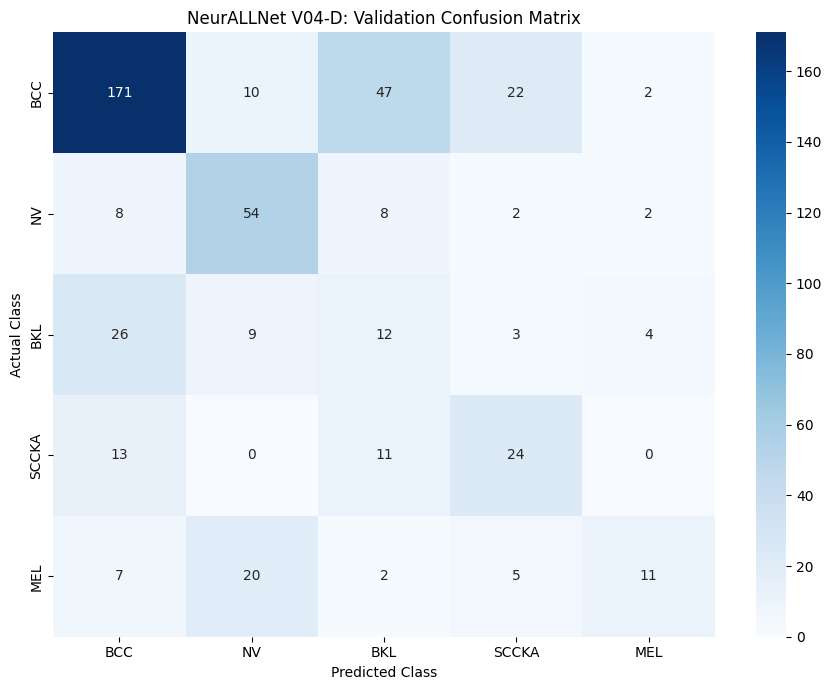


Final Validation Results
----------------------------------------
Accuracy:  0.5751
Macro F1:  0.4696
Samples:   473


In [39]:

# ==========================================
# NeurALLNet Version-04-D
# Best Checkpoint: Validation Classification Report
# ==========================================

import os
import torch
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

from spikingjelly.activation_based import functional


# ==========================================
# 1. Load Best Checkpoint
# ==========================================

checkpoint_path = "checkpoints_v4_d/best_model.pth"

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation Macro F1:",
    f"{checkpoint['best_val_f1']:.4f}"
)


# ==========================================
# 2. Generate Validation Predictions
# ==========================================

val_labels = []
val_preds = []

functional.reset_net(model)

with torch.no_grad():

    for clinical, dermoscopic, labels in val_loader:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)
        labels = labels.to(device)

        outputs = model(clinical, dermoscopic)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        val_labels.extend(
            labels.cpu().numpy()
        )

        val_preds.extend(
            predictions.cpu().numpy()
        )

        functional.reset_net(model)

        del clinical, dermoscopic, labels
        del outputs, predictions


# ==========================================
# 3. Classification Report
# ==========================================

class_indices = list(range(len(class_names)))

print("\n" + "=" * 65)
print("VALIDATION CLASSIFICATION REPORT")
print("=" * 65)

report = classification_report(
    val_labels,
    val_preds,
    labels=class_indices,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)


# ==========================================
# 4. Confusion Matrix
# ==========================================

cm = confusion_matrix(
    val_labels,
    val_preds,
    labels=class_indices
)

print("\nConfusion Matrix:")
print(cm)


# ==========================================
# 5. Visualize Confusion Matrix
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("NeurALLNet V04-D: Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


# ==========================================
# 6. Final Validation Metrics
# ==========================================

from sklearn.metrics import accuracy_score, f1_score

final_accuracy = accuracy_score(
    val_labels,
    val_preds
)

final_macro_f1 = f1_score(
    val_labels,
    val_preds,
    labels=class_indices,
    average="macro",
    zero_division=0
)

print("\nFinal Validation Results")
print("-" * 40)
print(f"Accuracy:  {final_accuracy:.4f}")
print(f"Macro F1:  {final_macro_f1:.4f}")
print(f"Samples:   {len(val_labels)}")


ACTUAL VS PREDICTED CLASS DISTRIBUTION
Class  Actual Count  Predicted Count  Actual %  Predicted %
  BCC           252              225     53.28        47.57
   NV            74               93     15.64        19.66
  BKL            54               80     11.42        16.91
SCCKA            48               56     10.15        11.84
  MEL            45               19      9.51         4.02


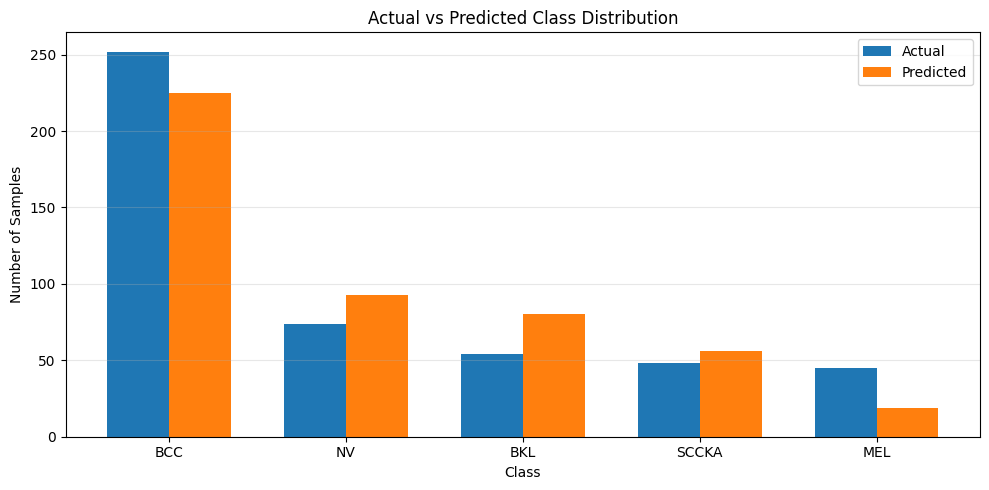

In [40]:

# ==========================================
# NeurALLNet V04-D
# Diagnostic 1: Actual vs Predicted Distribution
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Count actual and predicted samples
actual_counts = np.bincount(
    val_labels,
    minlength=len(class_names)
)

predicted_counts = np.bincount(
    val_preds,
    minlength=len(class_names)
)

# Create comparison table
distribution_df = pd.DataFrame({
    "Class": class_names,
    "Actual Count": actual_counts,
    "Predicted Count": predicted_counts
})

distribution_df["Actual %"] = (
    distribution_df["Actual Count"] /
    len(val_labels) * 100
)

distribution_df["Predicted %"] = (
    distribution_df["Predicted Count"] /
    len(val_preds) * 100
)

print("ACTUAL VS PREDICTED CLASS DISTRIBUTION")
print("=" * 65)
print(distribution_df.round(2).to_string(index=False))


# ==========================================
# Visual Comparison
# ==========================================

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    actual_counts,
    width,
    label="Actual"
)

plt.bar(
    x + width/2,
    predicted_counts,
    width,
    label="Predicted"
)

plt.xticks(x, class_names)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Actual vs Predicted Class Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


LIF Layers Found:
clinical_branch.stem.2
clinical_branch.block1.lif
clinical_branch.block2.lif
clinical_branch.block3.lif
clinical_branch.refine.4
dermoscopic_branch.stem.2
dermoscopic_branch.block1.lif
dermoscopic_branch.block2.lif
dermoscopic_branch.block3.lif
dermoscopic_branch.refine.4
classifier.2

LIF FIRING ACTIVITY
clinical_branch.stem.2                       : 0.095481 (9.55%)
clinical_branch.block1.lif                   : 0.023704 (2.37%)
clinical_branch.block2.lif                   : 0.015701 (1.57%)
clinical_branch.block3.lif                   : 0.015825 (1.58%)
clinical_branch.refine.4                     : 0.026051 (2.61%)
dermoscopic_branch.stem.2                    : 0.073609 (7.36%)
dermoscopic_branch.block1.lif                : 0.013148 (1.31%)
dermoscopic_branch.block2.lif                : 0.012282 (1.23%)
dermoscopic_branch.block3.lif                : 0.018585 (1.86%)
dermoscopic_branch.refine.4                  : 0.040674 (4.07%)
classifier.2                       

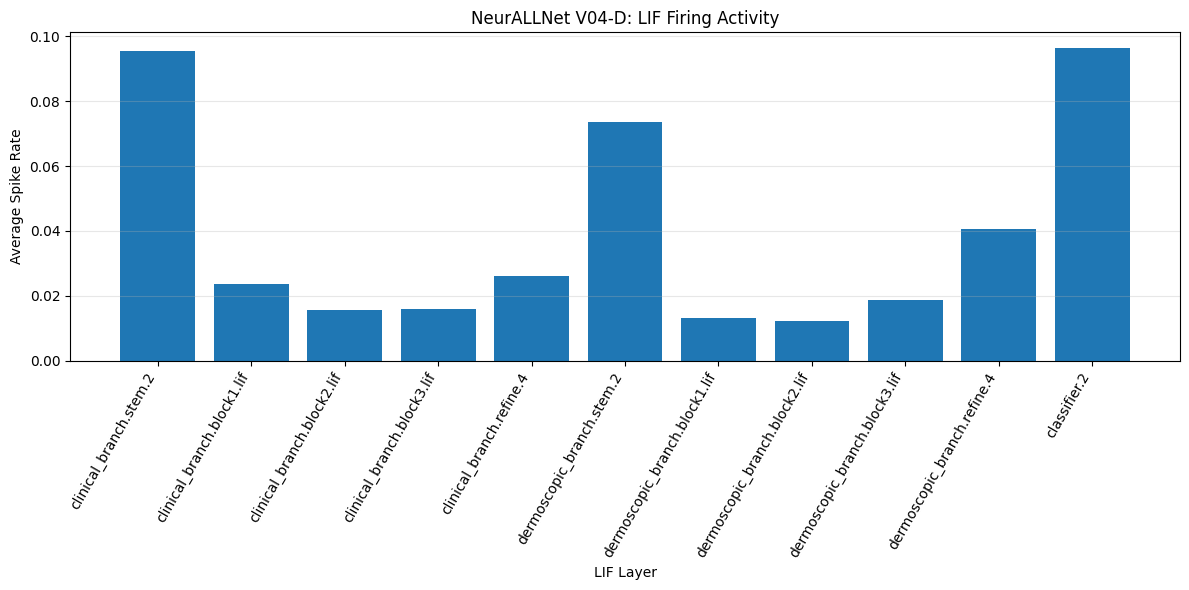

In [41]:

# ==========================================
# NeurALLNet V04-D
# Diagnostic 2: LIF Neuron Firing Activity
# ==========================================

from spikingjelly.activation_based import neuron, functional
import torch
import matplotlib.pyplot as plt


# ==========================================
# 1. Identify LIF Layers
# ==========================================

lif_layers = {
    name: module
    for name, module in model.named_modules()
    if isinstance(module, neuron.LIFNode)
}

print("LIF Layers Found:")
for name in lif_layers:
    print(name)


# ==========================================
# 2. Prepare Spike Statistics
# ==========================================

spike_sums = {name: 0.0 for name in lif_layers}
spike_elements = {name: 0 for name in lif_layers}


# ==========================================
# 3. Register Forward Hooks
# ==========================================

def make_spike_hook(layer_name):

    def hook(module, inputs, output):

        if isinstance(output, torch.Tensor):

            spikes = output.detach().float()

            spike_sums[layer_name] += spikes.sum().item()
            spike_elements[layer_name] += spikes.numel()

    return hook


hooks = []

for name, module in lif_layers.items():

    handle = module.register_forward_hook(
        make_spike_hook(name)
    )

    hooks.append(handle)


# ==========================================
# 4. Run Validation Data
# ==========================================

model.eval()
functional.reset_net(model)

with torch.no_grad():

    for clinical, dermoscopic, labels in val_loader:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)

        outputs = model(clinical, dermoscopic)

        functional.reset_net(model)

        del clinical, dermoscopic, labels, outputs


# ==========================================
# 5. Remove Hooks
# ==========================================

for handle in hooks:
    handle.remove()


# ==========================================
# 6. Calculate Firing Rates
# ==========================================

firing_rates = {}

for name in lif_layers:

    if spike_elements[name] > 0:

        rate = (
            spike_sums[name] /
            spike_elements[name]
        )

        firing_rates[name] = rate


print("\nLIF FIRING ACTIVITY")
print("=" * 65)

for name, rate in firing_rates.items():

    print(
        f"{name:45s}: {rate:.6f} "
        f"({rate * 100:.2f}%)"
    )


# ==========================================
# 7. Visualize Firing Rates
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    firing_rates.keys(),
    firing_rates.values()
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.ylabel("Average Spike Rate")
plt.xlabel("LIF Layer")
plt.title("NeurALLNet V04-D: LIF Firing Activity")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [42]:

# ==========================================
# NeurALLNet V04-D
# Diagnostic 3: Gradient Flow Analysis
# ==========================================

import torch
import pandas as pd
from spikingjelly.activation_based import functional

# Preserve original model mode
previous_mode = model.training

model.eval()
optimizer.zero_grad(set_to_none=True)
functional.reset_net(model)

# ==========================================
# 1. Forward and Backward Pass
# ==========================================

clinical, dermoscopic, labels = next(iter(train_loader))

clinical = clinical.to(device)
dermoscopic = dermoscopic.to(device)
labels = labels.to(device)

with torch.enable_grad():

    outputs = model(clinical, dermoscopic)

    loss = criterion(outputs, labels)

    loss.backward()


# ==========================================
# 2. Collect Gradient Statistics
# ==========================================

gradient_records = []

for name, parameter in model.named_parameters():

    if not parameter.requires_grad:
        continue

    if parameter.grad is None:

        gradient_records.append({
            "Parameter": name,
            "Gradient Norm": None,
            "Zero Gradient %": None,
            "Status": "Missing"
        })

        continue

    grad = parameter.grad.detach()

    grad_norm = grad.norm().item()

    zero_percentage = (
        (grad == 0).float().mean().item() * 100
    )

    if not torch.isfinite(grad).all():

        status = "Non-finite"

    elif grad_norm == 0:

        status = "Zero"

    else:

        status = "Present"

    gradient_records.append({
        "Parameter": name,
        "Gradient Norm": grad_norm,
        "Zero Gradient %": zero_percentage,
        "Status": status
    })


gradient_df = pd.DataFrame(gradient_records)


# ==========================================
# 3. Display Layer-wise Results
# ==========================================

print("\nGRADIENT FLOW ANALYSIS")
print("=" * 80)

print(
    gradient_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.8e}"
    )
)


# ==========================================
# 4. Branch-wise Summary
# ==========================================

def get_branch(name):

    if name.startswith("clinical_branch."):

        return "Clinical Branch"

    elif name.startswith("dermoscopic_branch."):

        return "Dermoscopic Branch"

    elif name.startswith("classifier."):

        return "Classifier"

    return "Other"


gradient_df["Branch"] = gradient_df["Parameter"].apply(
    get_branch
)

print("\nBRANCH-WISE GRADIENT SUMMARY")
print("=" * 65)

summary = gradient_df.groupby("Branch").agg(
    Total_Parameters=("Parameter", "count"),
    Missing_Gradients=(
        "Status",
        lambda x: (x == "Missing").sum()
    ),
    Zero_Gradients=(
        "Status",
        lambda x: (x == "Zero").sum()
    ),
    Non_Finite=(
        "Status",
        lambda x: (x == "Non-finite").sum()
    ),
    Mean_Gradient_Norm=(
        "Gradient Norm",
        "mean"
    )
)

print(summary)


# ==========================================
# 5. Cleanup
# ==========================================

optimizer.zero_grad(set_to_none=True)
functional.reset_net(model)

model.train(previous_mode)

del clinical, dermoscopic, labels
del outputs, loss

print("\nGradient diagnostic completed.")
print("No optimizer update was performed.")



GRADIENT FLOW ANALYSIS
                                       Parameter  Gradient Norm  Zero Gradient %  Status
                   clinical_branch.stem.0.weight 2.00220838e-01   0.00000000e+00 Present
                   clinical_branch.stem.1.weight 2.99739931e-02   0.00000000e+00 Present
                     clinical_branch.stem.1.bias 2.32131202e-02   0.00000000e+00 Present
    clinical_branch.block1.conv.depthwise.weight 1.62713811e-01   0.00000000e+00 Present
        clinical_branch.block1.conv.bn_dw.weight 2.70697568e-02   0.00000000e+00 Present
          clinical_branch.block1.conv.bn_dw.bias 2.66935956e-02   0.00000000e+00 Present
    clinical_branch.block1.conv.pointwise.weight 1.19305968e-01   0.00000000e+00 Present
        clinical_branch.block1.conv.bn_pw.weight 2.36895494e-02   0.00000000e+00 Present
          clinical_branch.block1.conv.bn_pw.bias 1.72941796e-02   0.00000000e+00 Present
   clinical_branch.block1.se.excitation.0.weight 3.19910683e-02   0.00000000e+00 Prese